In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import numpy as np
#Daten die gebraucht werden laden...
import pandas as pd
diebstahl=diebstahl = pd.read_csv(
    "Fahrraddiebstahl.csv",
    sep=",",
    dtype={"LOR": str},
    encoding='latin1'
)
bezirke = pd.read_csv(
    "bezirke.csv",
    sep=";",
    dtype={"PLR_ID": str},
    encoding='latin1'
)

In [2]:
#Wir möchten die beiden Datensätze über eine gemeinsame Kennung verbinden:

#Fahrraddiebstahl (LOR) → Bezirksübersicht (PLR_ID) → Bezirk
# IDs als Text speichern
diebstahl["LOR"] = diebstahl["LOR"].astype("string").str.zfill(8)
bezirke["PLR_ID"] = bezirke["PLR_ID"].astype("string").str.zfill(8)
#LOR	Gibt an, in welchem kleinen Gebiet (Planungsraum) das Fahrrad gestohlen wurde.
#PLR_ID	Ist die ID dieses kleinen Gebiets in deiner Bezirksübersicht.
#BEZ_ID	Ist die ID des gesamten Berliner Bezirks, z. B. Mitte.
# Tabellen verbinden
df = pd.merge(
    diebstahl, #tabelle links
    bezirke[["PLR_ID", "BEZ", "PGR", "BZR"]],#tabelle rechts
    left_on="LOR",# LOR wird verwendet
    right_on="PLR_ID",
    how="left",
    validate="many_to_one"
)

In [3]:
# Datum konvertieren
df["TATZEIT_ANFANG_DATUM"] = pd.to_datetime(
    df["TATZEIT_ANFANG_DATUM"],
    dayfirst=True,
    errors="coerce"
)

# Zusätzliche zeitliche Merkmale erzeugen
df["MONAT"] = df["TATZEIT_ANFANG_DATUM"].dt.month
df["WOCHENTAG"] = df["TATZEIT_ANFANG_DATUM"].dt.dayofweek

# Ungültige Datumswerte entfernen
df = df.dropna(subset=["TATZEIT_ANFANG_DATUM"])

print(df.head())

  ANGELEGT_AM TATZEIT_ANFANG_DATUM  TATZEIT_ANFANG_STUNDE TATZEIT_ENDE_DATUM  \
0  22.11.2026           2026-11-21                     14         21.11.2026   
1  22.11.2026           2026-11-22                     18         22.11.2026   
2  22.11.2026           2026-11-21                     17         21.11.2026   
3  22.11.2026           2026-11-21                     17         22.11.2026   
4  22.11.2026           2026-11-21                     14         22.11.2026   

   TATZEIT_ENDE_STUNDE       LOR  SCHADENSHOEHE VERSUCH ART_DES_FAHRRADS  \
0                   19  04501149           1400    Nein          Fahrrad   
1                   20  11400927           3000    Nein          Rennrad   
2                   18  08100311           1500    Nein          Fahrrad   
3                    1  06300526           3500    Nein     Mountainbike   
4                   14  12100103            844    Nein          Fahrrad   

             DELIKT                              ERFASSUNGSGRU

In [4]:
# Eingabevariablen
features = [
    "TATZEIT_ANFANG_STUNDE",
    "MONAT",
    "WOCHENTAG",
    "LOR",
    "PLR_ID",
    "BEZ",
    "BZR",
    "PGR"
]

X = df[features]

# Zielvariablen
y_schaden = df["SCHADENSHOEHE"]
y_fahrrad = df["ART_DES_FAHRRADS"]
y_delikt = df["DELIKT"]

In [5]:
# Nach Tatdatum sortieren
df = df.sort_values("TATZEIT_ANFANG_DATUM")

# 80/20-Aufteilung
split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

X_train = train[features]
X_test = test[features]

print("Trainingsdaten:", len(X_train))
print("Testdaten:", len(X_test))

Trainingsdaten: 26235
Testdaten: 6559


In [6]:
# Anzahl der Diebstähle je Ort und Stunde
hotspots = (
    df.groupby([
        "BEZ",
        "WOCHENTAG",
        "TATZEIT_ANFANG_STUNDE"
    ])
    .agg(
        ANZAHL=("DELIKT", "count"),
        DURCHSCHNITT_SCHADEN=("SCHADENSHOEHE", "mean")
    )
    .reset_index()
)

# Nach Anzahl der Diebstähle sortieren
hotspots = hotspots.sort_values(
    "ANZAHL",
    ascending=False
)

print(hotspots.head(20))

                           BEZ  WOCHENTAG  TATZEIT_ANFANG_STUNDE  ANZAHL  \
669                      Mitte          1                     18     102   
176   Friedrichshain-Kreuzberg          0                     18      95   
693                      Mitte          2                     18      95   
670                      Mitte          1                     19      93   
1047                    Pankow          3                     18      92   
741                      Mitte          4                     18      91   
223   Friedrichshain-Kreuzberg          2                     18      91   
247   Friedrichshain-Kreuzberg          3                     18      91   
717                      Mitte          3                     18      87   
645                      Mitte          0                     18      86   
200   Friedrichshain-Kreuzberg          1                     18      85   
659                      Mitte          1                      8      85   
224   Friedr

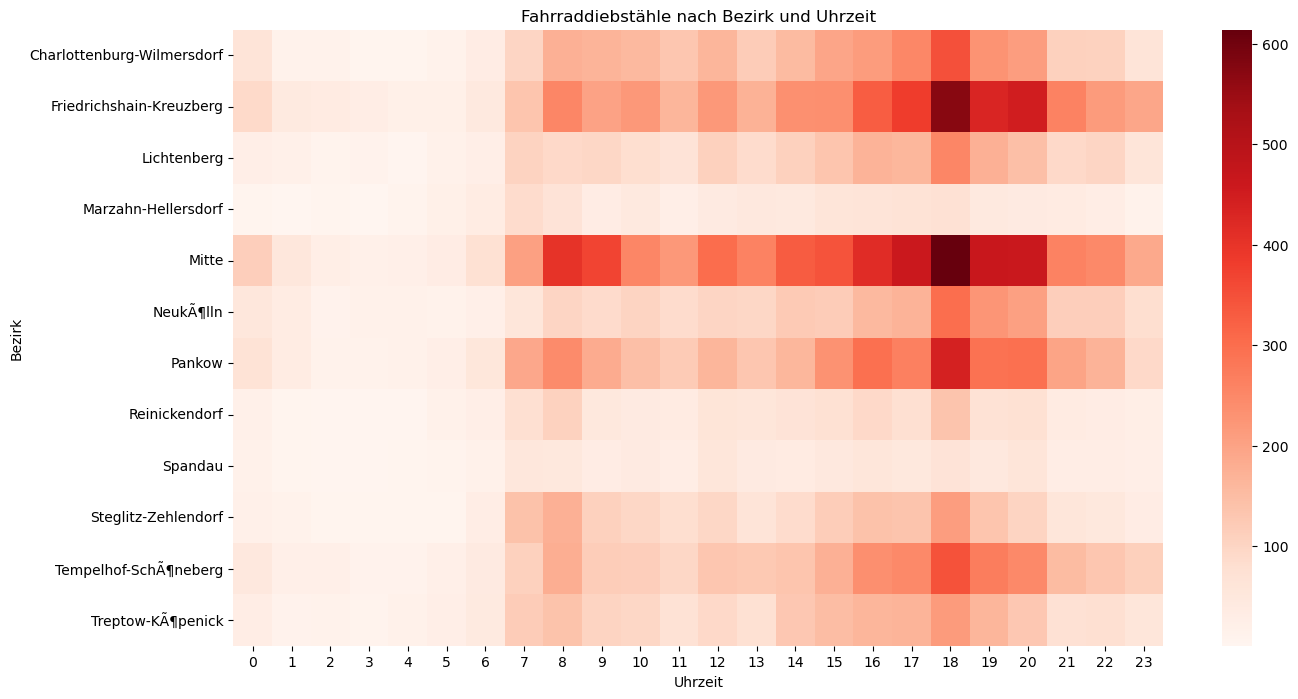

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_data = df.pivot_table(
    index="BEZ",
    columns="TATZEIT_ANFANG_STUNDE",
    values="DELIKT",
    aggfunc="count",
    fill_value=0
)

plt.figure(figsize=(15, 8))

sns.heatmap(
    heatmap_data,
    cmap="Reds"
)

plt.title("Fahrraddiebstähle nach Bezirk und Uhrzeit")
plt.xlabel("Uhrzeit")
plt.ylabel("Bezirk")

plt.show()

In [8]:
df["ART_DES_FAHRRADS"].value_counts() 


ART_DES_FAHRRADS
Herrenfahrrad        11047
Damenfahrrad          5983
Fahrrad               5927
Mountainbike          2254
Rennrad               1708
Citybike              1530
Trekkingrad           1529
Kinderfahrrad         1458
diverse Fahrräder      767
Lastenfahrrad          230
Hollandrad             172
Klapprad               172
BMX                     16
Liegerad                 1
Name: count, dtype: int64

In [9]:
df["DELIKT"].value_counts()

DELIKT
Fahrraddiebstahl             31216
Keller- und Bodeneinbruch     1578
Name: count, dtype: int64

In [14]:
import time

start = time.time()

modell = CatBoostClassifier(
    iterations=100,
    depth=4,
    learning_rate=0.1,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    verbose=10,
    random_seed=42,
    thread_count=4
)

print("Training startet...")

modell.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

print("Training abgeschlossen!")
print("Laufzeit:", round(time.time() - start, 2), "Sekunden")

Training startet...
0:	learn: 2.3810185	total: 1.64s	remaining: 2m 41s
10:	learn: 2.3038426	total: 13.4s	remaining: 1m 48s
20:	learn: 2.2783966	total: 25.3s	remaining: 1m 35s
30:	learn: 2.2337136	total: 36.4s	remaining: 1m 20s
40:	learn: 2.2186604	total: 46.3s	remaining: 1m 6s
50:	learn: 2.1967647	total: 57.7s	remaining: 55.5s
60:	learn: 2.1847111	total: 1m 10s	remaining: 45.1s
70:	learn: 2.1749522	total: 1m 23s	remaining: 34.1s
80:	learn: 2.1680720	total: 1m 36s	remaining: 22.7s
90:	learn: 2.1616850	total: 1m 47s	remaining: 10.7s
99:	learn: 2.1548355	total: 2m	remaining: 0us
Training abgeschlossen!
Laufzeit: 121.13 Sekunden


In [15]:
vorhersage = modell.predict(X_test).ravel()

print("Accuracy:",
      accuracy_score(y_test, vorhersage))

print("Macro-F1:",
      f1_score(y_test, vorhersage, average="macro"))

print(classification_report(
    y_test,
    vorhersage,
    zero_division=0
))

Accuracy: 0.09894801036743406
Macro-F1: 0.06726307532490765
                   precision    recall  f1-score   support

         Citybike       0.14      0.02      0.03      1132
     Damenfahrrad       0.02      0.16      0.03       144
          Fahrrad       0.27      0.31      0.29      1248
    Herrenfahrrad       0.01      0.00      0.00       256
    Kinderfahrrad       0.08      0.04      0.05       266
    Lastenfahrrad       0.02      0.26      0.04        99
     Mountainbike       0.16      0.02      0.03      1030
          Rennrad       0.16      0.11      0.13       866
         Sonstige       0.05      0.05      0.05       265
      Trekkingrad       0.15      0.02      0.03      1114
diverse Fahrräder       0.02      0.21      0.04       139

         accuracy                           0.10      6559
        macro avg       0.10      0.11      0.07      6559
     weighted avg       0.15      0.10      0.09      6559

